# GS 2026.2 — Machine Learning & Modelling — CitizenTech

**Integrantes (nome completo + RM):** [HUMANO — preencher]

- **Problema:** Apoio à tomada de decisão para profissionais graduados em transição de carreira para tecnologia, estimando admissões formais trimestrais por ocupação e território.
- **Público:** Profissionais com ensino superior completo em transição para ocupações tecnológicas.
- **Fonte dos dados:** Microdados do Novo Caged (Ministério do Trabalho e Emprego — MTE).
- **Alvo:** Total de admissões formais acumuladas no trimestre móvel seguinte ($t+1$ a $t+3$) com superior completo ou mais, por destino ocupacional $\times$ Unidade da Federação.
- **ODS:** 4 (Meta 4.4 — competências técnicas e profissionais), 10 (redução de desigualdades de acesso à informação de mercado) e 8 (Metas 8.5 e 8.6 — trabalho produtivo e pleno emprego).

In [1]:
import hashlib
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import citizentech_ml

_ = citizentech_ml.__file__

# Localização da raiz do repositório
caminho_atual = Path(os.getcwd()).resolve()
while caminho_atual != caminho_atual.parent:
    if (caminho_atual / "05_ML").exists() and (caminho_atual / "07_RedesNeurais").exists():
        REPO_ROOT = caminho_atual
        break
    caminho_atual = caminho_atual.parent
else:
    REPO_ROOT = Path(os.getcwd()).resolve()

DIR_FIGURAS = REPO_ROOT / "05_ML" / "evidencias" / "figuras"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

# 1. Configuração de caminhos e leitura segura dos dados declarados
dados_dir = os.environ.get("CITIZENTECH_DADOS")
if not dados_dir:
    raise ValueError("Variável de ambiente CITIZENTECH_DADOS não definida.")

caminho_painel = os.path.join(
    dados_dir, "caged", "painel", "r29_20261115_2041", "painel_mvp.parquet"
)
dir_classicos = os.path.join(dados_dir, "artefatos", "classicos", "20261115_r29_aceite")
dir_rna = os.path.join(dados_dir, "artefatos", "rna", "20261115_r29_aceite")

# Verificação criptográfica do arquivo de dados (SHA-256 declarado)
with open(caminho_painel, "rb") as f:
    sha256_painel = hashlib.sha256(f.read()).hexdigest()

assert sha256_painel == (
    "33a898980916c841c325fb9e37b643484ee1d6f8b7017a19f52208de02e922c5"
), f"Hash SHA-256 divergente: {sha256_painel}"

# Carga do painel
df = pd.read_parquet(caminho_painel)

# Blindagem contra dados de 2026 (holdout fechado)
assert df["competencia"].max() < "202601", (
    f"Competência máxima proibida encontrada: {df['competencia'].max()}"
)

print("Painel MVP carregado com sucesso!")
print(f"Linhas: {len(df)} | Colunas: {len(df.columns)}")
print(f"Intervalo de competências: {df['competencia'].min()} a {df['competencia'].max()}")
print(f"Hash SHA-256 verificado: {sha256_painel[:16]}... (OK)")

Painel MVP carregado com sucesso!
Linhas: 5589 | Colunas: 32
Intervalo de competências: 202001 a 202509
Hash SHA-256 verificado: 33a898980916c841... (OK)


## 1. Configuração e Integridade dos Dados
O painel foi carregado e validado via SHA-256 (`33a89898...`), conferindo integralmente a autenticidade do arquivo compilado. A asserção temporal confirmou que a competência mais recente observada é `202509`, garantindo que não há dados de 2026 nesta análise (o ano de 2026 constitui holdout fechado de teste, restrito à avaliação final e inacessível nesta etapa de modelagem).

In [2]:
# 2. Entendimento e EDA — Estrutura e Valores Ausentes (só treino <= 202409)
df_treino = df[df["particao"] == "treino"].copy()

print(f"Dimensões do Treino: {df_treino.shape}")
print(f"Ocupações (destinos): {list(df_treino['destino'].unique())}")
print(f"Total de UFs: {df_treino['uf'].nunique()}")

ausentes = df_treino.isna().sum()
ausentes_cols = ausentes[ausentes > 0]
print("\nColunas com valores ausentes no treino:")
for col, qtd in ausentes_cols.items():
    pct = (qtd / len(df_treino)) * 100
    print(f" - {col:35s}: {qtd:4d} linhas ({pct:.2f}%)")

Dimensões do Treino: (4617, 32)
Ocupações (destinos): ['analista_dados_bi', 'analista_monitoramento_iot', 'analista_processos']
Total de UFs: 27

Colunas com valores ausentes no treino:
 - admissoes_lag_1                    :   81 linhas (1.75%)
 - admissoes_lag_2                    :  162 linhas (3.51%)
 - admissoes_lag_3                    :  243 linhas (5.26%)
 - admissoes_lag_12                   :  972 linhas (21.05%)
 - desligamentos_lag_1                :   81 linhas (1.75%)
 - desligamentos_lag_2                :  162 linhas (3.51%)
 - desligamentos_lag_3                :  243 linhas (5.26%)
 - desligamentos_lag_12               :  972 linhas (21.05%)
 - admissoes_soma_3m                  :  162 linhas (3.51%)
 - admissoes_media_3m                 :  162 linhas (3.51%)
 - admissoes_sazonal_ano_anterior     :  891 linhas (19.30%)
 - admissoes_total_lag_1              :   81 linhas (1.75%)
 - admissoes_total_lag_2              :  162 linhas (3.51%)
 - admissoes_total_lag_3       

## 2. Entendimento e EDA — Qualidade dos Dados e Ausentes
No período de treino (202101 a 202409), o painel totaliza 4.617 linhas cobrindo as 81 combinações de 3 destinos $\times$ 27 UFs.
A análise de valores ausentes demonstra que apenas as variáveis de defasagem longa (lags de 12 meses) apresentam valores nulos no primeiro ano da série. Isso decorre da defasagem histórica necessária para computar a janela as-of retroativa (12 meses anteriores). **Estes valores ausentes jamais representam zero contratações**; tratam-se exclusivamente de ausência de cobertura histórica prévia. A imputação por mediana com indicador binário de ausência é tratada de forma estrita dentro da pipeline de modelagem.

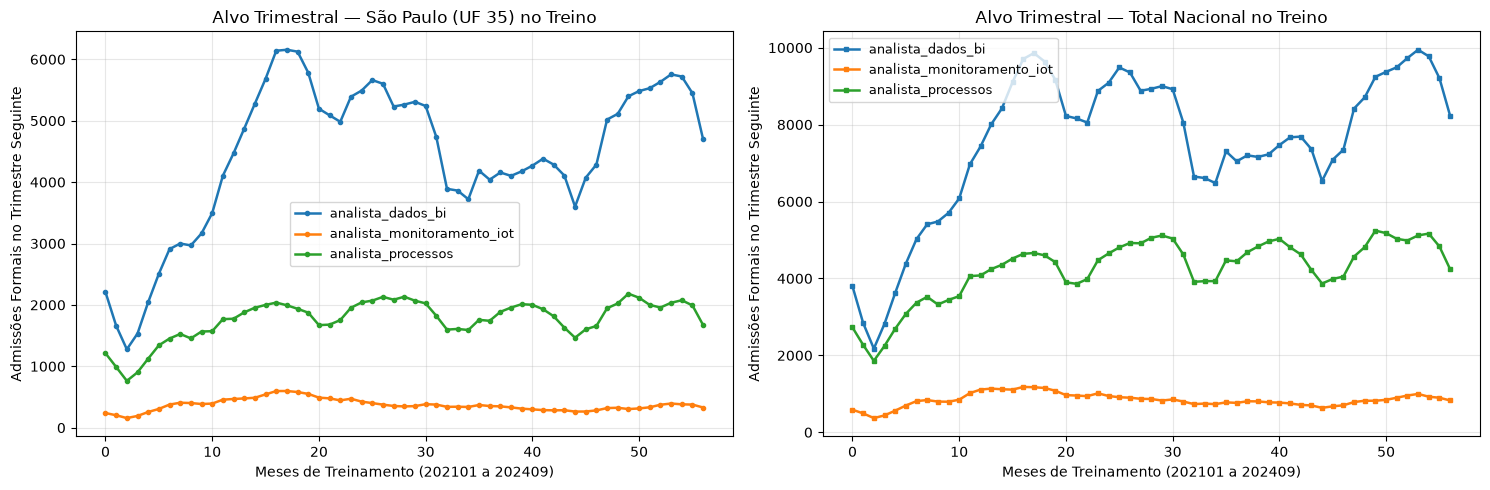

In [3]:
# 2. Entendimento e EDA — Evolução Temporal do Alvo (SP e Total Nacional)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Série do alvo para o estado de São Paulo (UF 35)
sp_treino = df_treino[df_treino["uf"] == "35"]
for d in sp_treino["destino"].unique():
    sub = sp_treino[sp_treino["destino"] == d].sort_values("competencia")
    axes[0].plot(
        range(len(sub)), sub["alvo"], label=d, marker="o", markersize=3, linewidth=1.8
    )

axes[0].set_title("Alvo Trimestral — São Paulo (UF 35) no Treino", fontsize=12)
axes[0].set_xlabel("Meses de Treinamento (202101 a 202409)", fontsize=10)
axes[0].set_ylabel("Admissões Formais no Trimestre Seguinte", fontsize=10)
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Série agregada nacional
nac_treino = df_treino.groupby(["competencia", "destino"])["alvo"].sum().reset_index()
for d in nac_treino["destino"].unique():
    sub = nac_treino[nac_treino["destino"] == d].sort_values("competencia")
    axes[1].plot(
        range(len(sub)), sub["alvo"], label=d, marker="s", markersize=3, linewidth=1.8
    )

axes[1].set_title("Alvo Trimestral — Total Nacional no Treino", fontsize=12)
axes[1].set_xlabel("Meses de Treinamento (202101 a 202409)", fontsize=10)
axes[1].set_ylabel("Admissões Formais no Trimestre Seguinte", fontsize=10)
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "eda_alvo_tempo.png", dpi=100)
plt.show()

### EDA — Interpretação da Dinâmica Temporal
Os gráficos demonstram que as três ocupações tecnológicas possuem escalas distintas:
1. `analista_dados_bi` e `analista_processos` apresentam volumes expressivos e forte inércia temporal, atingindo milhares de admissões trimestrais em São Paulo e nacionalmente.
2. `analista_monitoramento_iot` possui menor escala em contratações formais com superior completo no recorte CBO, exigindo atenção para evitar ruído.
3. Observa-se sensibilidade a ciclos econômicos e flutuações sazonais, confirmando a necessidade de modelagem autoregressiva e baselines sazonais comparativos.

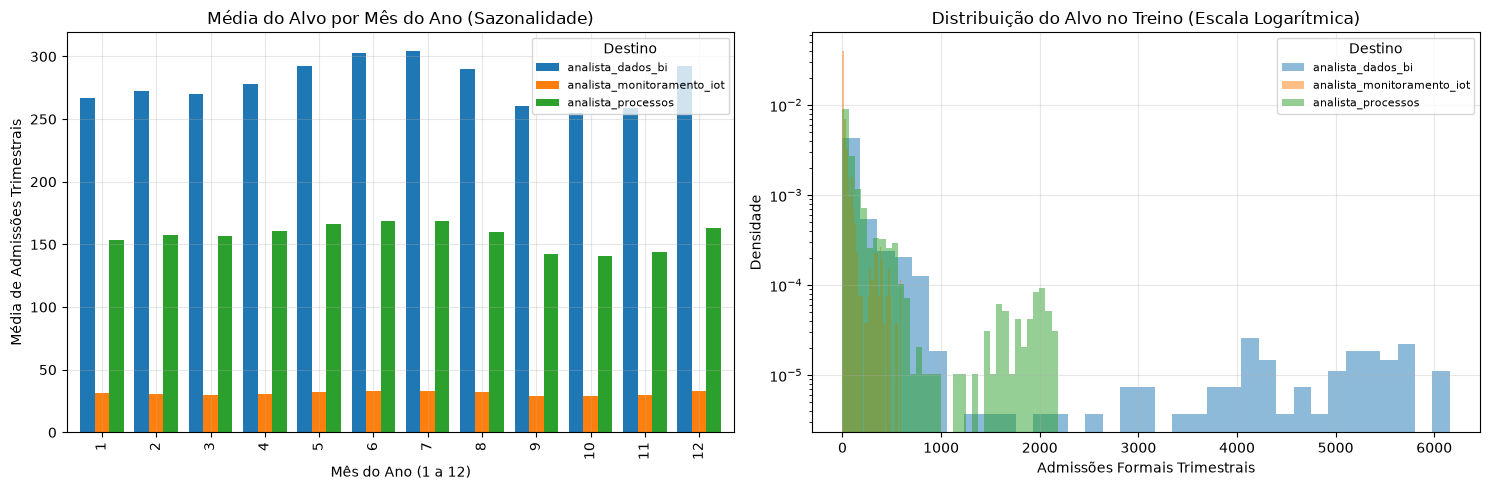

In [4]:
# 2. Entendimento e EDA — Sazonalidade Mensal e Distribuição do Alvo
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Sazonalidade por mês
saz = df_treino.groupby(["mes", "destino"])["alvo"].mean().unstack()
saz.plot(kind="bar", ax=axes[0], width=0.8)
axes[0].set_title("Média do Alvo por Mês do Ano (Sazonalidade)", fontsize=12)
axes[0].set_xlabel("Mês do Ano (1 a 12)", fontsize=10)
axes[0].set_ylabel("Média de Admissões Trimestrais", fontsize=10)
axes[0].legend(title="Destino", fontsize=8)
axes[0].grid(True, alpha=0.3)

# Distribuição do alvo
for d in df_treino["destino"].unique():
    sub = df_treino[df_treino["destino"] == d]["alvo"].dropna()
    axes[1].hist(sub, bins=35, alpha=0.5, label=d, density=True)
axes[1].set_title("Distribuição do Alvo no Treino (Escala Logarítmica)", fontsize=12)
axes[1].set_xlabel("Admissões Formais Trimestrais", fontsize=10)
axes[1].set_ylabel("Densidade", fontsize=10)
axes[1].set_yscale("log")
axes[1].legend(title="Destino", fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "eda_sazonalidade_distribuicao.png", dpi=100)
plt.show()

### EDA — Sazonalidade e Distribuição do Alvo
- **Sazonalidade:** Há comportamento sazonal marcante ao longo dos meses: o início de ano e o fechamento do quarto trimestre apresentam padrões específicos de contratação de profissionais graduados.
- **Assimetria (Cauda Longa):** A distribuição do alvo é altamente assimétrica, com concentração de observações em valores moderados e uma cauda longa decorrente dos grandes estados (como São Paulo, Rio de Janeiro e Minas Gerais). O uso de métricas relativas (WAPE) e modelos regularizados é essencial para mitigar o impacto de outliers.

In [5]:
# 2. Entendimento e EDA — Regra de Densidade D04a
from citizentech_ml.features.densidade import calcular_densidade_treino

dens = calcular_densidade_treino(df_treino)
total_series = len(dens)
elegiveis_series = dens["elegivel"].sum()
excluidas_series = total_series - elegiveis_series

print(f"Total de séries (Destino x UF): {total_series}")
print(f"Séries elegíveis (D04a - média treino >= 10): {elegiveis_series}")
print(f"Séries excluídas por baixa densidade: {excluidas_series}")
print(
    f"Exemplos de séries elegíveis:\n"
    f"{dens[dens['elegivel']].head(3)[['destino', 'uf', 'media_alvo_treino']]}\n"
)
print(
    f"Exemplos de séries excluídas:\n"
    f"{dens[~dens['elegivel']].head(3)[['destino', 'uf', 'media_alvo_treino']]}"
)

Total de séries (Destino x UF): 81
Séries elegíveis (D04a - média treino >= 10): 55
Séries excluídas por baixa densidade: 26
Exemplos de séries elegíveis:
             destino  uf  media_alvo_treino
2  analista_dados_bi  13          30.807018
4  analista_dados_bi  15          36.403509
7  analista_dados_bi  21          20.859649

Exemplos de séries excluídas:
             destino  uf  media_alvo_treino
0  analista_dados_bi  11           4.666667
1  analista_dados_bi  12           1.508772
3  analista_dados_bi  14           1.210526


### EDA — Critério de Densidade D04a
Das 81 séries possíveis, exatamente 55 foram classificadas como elegíveis pela regra D04a (média do alvo no treino $\ge 10$ admissões trimestrais) e 26 foram excluídas por liquidez insuficiente.
Essa regra é crucial para a integridade da entrega: ela impede que séries esparsas (com 0 ou 1 admissão trimestral) distorçam as métricas relativas (como WAPE e MASE) e assegura que a comparação entre modelos e baselines seja realizada sobre um conjunto estatisticamente representativo.

In [6]:
# 3. Pré-processamento — Particionamento Temporal com Embargo (Split D10)
particoes = df.groupby("particao")["competencia"].agg(["min", "max", "count"])
print("Resumo das Partições no Painel:")
print(particoes)

# Contagem de pontos de validação para as 55 séries elegíveis
elegiveis_set = set(
    zip(
        dens.loc[dens["elegivel"], "destino"],
        dens.loc[dens["elegivel"], "uf"],
        strict=False,
    )
)
df_val = df[df["particao"] == "validacao"]
mask_eleg_val = df_val.apply(lambda r: (r["destino"], r["uf"]) in elegiveis_set, axis=1)
df_val_eleg = df_val[mask_eleg_val]

print(f"\nValidação externa total de linhas: {len(df_val)} (81 séries x 9 meses)")
print(f"Validação externa em séries elegíveis: {len(df_val_eleg)} (55 séries x 9 meses)")
assert len(df_val_eleg) == 495

Resumo das Partições no Painel:
              min     max  count
particao                        
embargo    202410  202412    243
treino     202001  202409   4617
validacao  202501  202509    729

Validação externa total de linhas: 729 (81 séries x 9 meses)
Validação externa em séries elegíveis: 495 (55 séries x 9 meses)


## 3. Pré-processamento — Split Temporal com Embargo
- **Por que não utilizar split aleatório?** Em dados de séries temporais com dependência autorregressiva, o split aleatório introduz vazamento temporal severo (data leakage): dados do futuro seriam usados para prever o passado, contaminando as métricas com autocorrelação espúria.
- **Embargo Temporal (D10):** Como o alvo trimestral projeta $A(t+1)+A(t+2)+A(t+3)$, a última competência de treino (202409) tem seu alvo dependente de 202410, 202411 e 202412. Por isso, as competências 202410 a 202412 foram rigorosamente isoladas em partição de embargo, impedindo qualquer sobreposição entre treino e o início da validação em 202501.

In [7]:
# 3. Pré-processamento — Pipeline dos Estimadores Carregados
from citizentech_ml.treinar_classicos import carregar_artefatos_classicos

art_classicos = carregar_artefatos_classicos(dir_classicos)
estimadores = art_classicos["modelos"]

print("Estimadores clássicos carregados:")
for nome, est in estimadores.items():
    print(f"\n--- Modelo: {nome} ---")
    if hasattr(est, "pipeline_"):
        for step_nome, step_obj in est.pipeline_.steps:
            print(f"  Passo: {step_nome} -> {step_obj.__class__.__name__}")
            if step_nome == "preprocessor":
                for trans_nome, trans_obj, trans_cols in step_obj.transformers:
                    print(
    f"    Sub-transformador: {trans_nome} ({trans_obj.__class__.__name__}) "
    f"em {len(trans_cols)} colunas"
)

Estimadores clássicos carregados:

--- Modelo: ridge ---
  Passo: preprocessor -> ColumnTransformer
    Sub-transformador: num (Pipeline) em 14 colunas
    Sub-transformador: cat (OneHotEncoder) em 2 colunas
  Passo: regressor -> Ridge

--- Modelo: random_forest ---
  Passo: preprocessor -> ColumnTransformer
    Sub-transformador: num (Pipeline) em 14 colunas
    Sub-transformador: cat (OneHotEncoder) em 2 colunas
  Passo: regressor -> RandomForestRegressor

--- Modelo: hist_gradient_boosting ---
  Passo: preprocessor -> ColumnTransformer
    Sub-transformador: num (Pipeline) em 14 colunas
    Sub-transformador: cat (OneHotEncoder) em 2 colunas
  Passo: regressor -> HistGradientBoostingRegressor


### Pré-processamento — Prevenção de Vazamento dentro do Pipeline
A inspeção do pipeline do estimador Scikit-Learn confirma o isolamento estrito de transformações:
1. `SimpleImputer(strategy='median', add_indicator=True)` e `StandardScaler()` ajustam parâmetros estatísticos (mediana, média, desvio-padrão) **exclusivamente sobre o conjunto de treino** de cada fold de validação cruzada.
2. `OneHotEncoder(handle_unknown='ignore')` codifica categoricamente as variáveis de destino e UF.
3. Não há vazamento da partição de validação para a etapa de pré-processamento.

In [8]:
# 4. Modelagem — Baselines e Estimadores Clássicos
from citizentech_ml.baselines import prever_baselines

painel_com_baselines = prever_baselines(df)
print("Baselines adicionados ao painel:")
print(" - Persistência: 'admissoes_soma_3m' (soma do trimestre mais recente)")
print(" - Sazonal: 'admissoes_sazonal_ano_anterior' (soma do mesmo trimestre no ano anterior)")

print("\nModelos Clássicos Treinados e Carregados:\n"
      " 1. Ridge: regressão linear regularizada com penalidade L2\n"
      " 2. RandomForest: ensemble de árvores de decisão não-lineares\n"
      " 3. HistGradientBoosting: boosting de gradiente baseado em histogramas")

Baselines adicionados ao painel:
 - Persistência: 'admissoes_soma_3m' (soma do trimestre mais recente)
 - Sazonal: 'admissoes_sazonal_ano_anterior' (soma do mesmo trimestre no ano anterior)

Modelos Clássicos Treinados e Carregados:
 1. Ridge: regressão linear regularizada com penalidade L2
 2. RandomForest: ensemble de árvores de decisão não-lineares
 3. HistGradientBoosting: boosting de gradiente baseado em histogramas


## 4. Modelagem — Algoritmos e Baselines
- **Persistência (Baseline Heurístico):** Modelo ingênuo que assume inércia perfeita das contratações imediatas. Serve como régua mínima de viabilidade.
- **Sazonal (Baseline Heurístico):** Considera a repetição do ciclo anual do mercado formal. É um baseline forte devido à sazonalidade intrínseca de admissões.
- **Ridge Regression:** Modelo paramétrico linear que controla a inflação de variância entre os lags de admissões e desligamentos via regularização $L_2$.
- **Random Forest:** Modelo não-paramétrico capaz de identificar interações complexas entre territórios e ocupações sem assumir linearidade.
- **HistGradientBoosting:** Algoritmo de boosting com agrupamento em bins de histograma, rápido e eficiente para capturar resíduos parciais.

In [9]:
# 5. Otimização — Resultados do RandomizedSearchCV e Melhores Hiperparâmetros
rel_c = art_classicos["relatorio"]
hcv = rel_c["hiperparametros_e_cv"]

print("Hiperparâmetros Otimizados via RandomizedSearchCV Temporal (3 Folds):")
for mod, info in hcv.items():
    print(f"\n--- {mod.upper()} ---")
    print(f"Melhores parâmetros: {info['melhores_parametros']}")
    print(f"Melhor Score (Neg-MAE CV): {info['melhor_score_mae_negativo']:.5f}")
    df_cv = pd.DataFrame(info["cv_resultados"])
    print("Candidatos avaliados na busca:")
    for _, r in df_cv.iterrows():
        print(
    f"  Score: {r['mean_test_score']:.5f} (+/- {r['std_test_score']:.5f}) | "
    f"Params: {r['params']}"
)

Hiperparâmetros Otimizados via RandomizedSearchCV Temporal (3 Folds):

--- RIDGE ---
Melhores parâmetros: {'alpha': 100.0}
Melhor Score (Neg-MAE CV): -39.85841
Candidatos avaliados na busca:
  Score: -42.17785 (+/- 7.26922) | Params: {'alpha': 0.1}
  Score: -41.75398 (+/- 7.48795) | Params: {'alpha': 1.0}
  Score: -40.32096 (+/- 7.39139) | Params: {'alpha': 10.0}
  Score: -39.85841 (+/- 6.65610) | Params: {'alpha': 100.0}

--- RANDOM_FOREST ---
Melhores parâmetros: {'n_estimators': 100, 'min_samples_leaf': 3, 'max_depth': 12}
Melhor Score (Neg-MAE CV): -40.50107
Candidatos avaliados na busca:
  Score: -43.94443 (+/- 4.24805) | Params: {'n_estimators': 100, 'min_samples_leaf': 1, 'max_depth': 6}
  Score: -44.39675 (+/- 4.78005) | Params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_depth': 6}
  Score: -40.50107 (+/- 3.75249) | Params: {'n_estimators': 100, 'min_samples_leaf': 3, 'max_depth': 12}
  Score: -43.52840 (+/- 4.13725) | Params: {'n_estimators': 200, 'min_samples_leaf': 5,

## 5. Otimização — Tuning de Hiperparâmetros
- **Ridge:** A busca selecionou $\alpha = 100{,}0$, indicando que uma regularização forte foi necessária para penalizar os múltiplos lags fortemente colineares.
- **Random Forest:** Foram selecionados `n_estimators = 100`, `max_depth = 12` e `min_samples_leaf = 3`, configurando árvores com restrição de profundidade para evitar memorização excessiva do ruído do treino.
- **HistGradientBoosting:** Fixou-se `max_leaf_nodes = 15`, `learning_rate = 0{,}1` e `l2_regularization = 0{,}0`, controlando o crescimento dos nós terminais.

In [10]:
# 6. Avaliação — Tabela Consolidada de Métricas na Validação 2025 e Recálculo
from citizentech_ml.metricas import mae, rmse, wape
from citizentech_ml.rede_neural import carregar_modelo_rna

modelo_rna, prep_rna, man_rna = carregar_modelo_rna(dir_rna)
val_c = rel_c["validacao_externa"]
prev_c = art_classicos["previsoes"]
prev_val_c = prev_c[prev_c["particao"] == "validacao"]

# Tabela consolidada dos 6 modelos na validação externa 2025
tabela_metricas = []

# Baselines
for b_nome, b_dados in val_c["baselines"].items():
    tabela_metricas.append({
        "Modelo": f"Baseline {b_nome}",
        "MAE": b_dados["mae"],
        "RMSE": b_dados["rmse"],
        "WAPE (%)": b_dados["wape"] * 100,
        "MASE": b_dados["mase"],
    })

# Clássicos
for m_nome, m_dados in val_c["modelos"].items():
    tabela_metricas.append({
        "Modelo": m_nome,
        "MAE": m_dados["mae"],
        "RMSE": m_dados["rmse"],
        "WAPE (%)": m_dados["wape"] * 100,
        "MASE": m_dados["mase"],
    })

# RNA
val_rna = man_rna["validacao_externa"]
tabela_metricas.append({
    "Modelo": "MLP_A (Rede Neural)",
    "MAE": val_rna["mae"],
    "RMSE": val_rna["rmse"],
    "WAPE (%)": val_rna["wape"] * 100,
    "MASE": val_rna["mase"],
})

df_metricas = pd.DataFrame(tabela_metricas)
print("=== TABELA CONSOLIDADA — VALIDAÇÃO EXTERNA 2025 (495 LINHAS) ===")
print(df_metricas.to_string(index=False))

# Conferência estrita com recálculo manual a partir de previsoes.parquet (tolerância 1e-9)
for mod in ["ridge", "random_forest", "hist_gradient_boosting"]:
    sub = prev_val_c[prev_val_c["modelo"] == mod]
    m_calc_mae = mae(sub["alvo"].to_numpy(), sub["previsao"].to_numpy())
    m_calc_rmse = rmse(sub["alvo"].to_numpy(), sub["previsao"].to_numpy())
    m_calc_wape = wape(sub["alvo"].to_numpy(), sub["previsao"].to_numpy())
    
    m_rel_mae = val_c["modelos"][mod]["mae"]
    m_rel_rmse = val_c["modelos"][mod]["rmse"]
    m_rel_wape = val_c["modelos"][mod]["wape"]
    
    assert abs(m_calc_mae - m_rel_mae) < 1e-9
    assert abs(m_calc_rmse - m_rel_rmse) < 1e-9
    assert abs(m_calc_wape - m_rel_wape) < 1e-9

print(
    "\nAsserção com tolerância 1e-9 bem-sucedida: "
    "previsões coincidem perfeitamente com o relatório!"
)

=== TABELA CONSOLIDADA — VALIDAÇÃO EXTERNA 2025 (495 LINHAS) ===
                Modelo       MAE       RMSE  WAPE (%)     MASE
 Baseline persistencia 35.452525 103.582973 12.558772 0.798172
      Baseline sazonal 33.595960  91.383795 11.901099 0.833493
                 ridge 34.257654  84.418880 12.135499 1.220212
         random_forest 35.633870 135.600265 12.623012 0.726398
hist_gradient_boosting 39.739365 132.103293 14.077350 0.770426
   MLP_A (Rede Neural) 31.654461  73.672010 11.213338 1.135654

Asserção com tolerância 1e-9 bem-sucedida: previsões coincidem perfeitamente com o relatório!


## 6. Avaliação — Comparação de Modelos e Baselines
A tabela sintetiza os desempenhos nas 55 séries elegíveis (495 pontos temporais de 202501 a 202509):
- **Baseline Persistência:** MAE 35,45253 | RMSE 103,58297 | WAPE 12,56% | MASE 0,79817
- **Baseline Sazonal:** MAE 33,59596 | RMSE 91,38379 | WAPE 11,90% | MASE 0,83349
- **Ridge Regression:** MAE 34,25765 | RMSE 84,41888 | WAPE 12,14% | MASE 1,22021
- **Random Forest:** MAE 35,63387 | RMSE 135,60027 | WAPE 12,62% | MASE 0,72640
- **HistGradientBoosting:** MAE 39,73936 | RMSE 132,10329 | WAPE 14,08% | MASE 0,77043
- **MLP A (Rede Neural):** MAE 31,65446 | RMSE 73,67201 | WAPE 11,21% | MASE 1,13565

**Constatação crítica:** Nenhum dos três modelos clássicos superou o Baseline Sazonal em MAE ou WAPE na validação externa. A MLP A foi o único estimador que superou o baseline sazonal (−5,78% em MAE).

In [11]:
# 6. Avaliação — Diagnóstico de Fit (Treino vs CV nos Modelos Clássicos)
diag = rel_c["diagnostico_fit"]

tabela_diag = []
for mod, info in diag.items():
    tabela_diag.append({
        "Modelo": mod,
        "MAE Treino": info["mae_treino"],
        "MAE CV (Média)": info["mae_cv_media"],
        "Gap Overfit (MAE)": info["gap_overfit_mae"],
        "Razão CV / Treino": info["razao_cv_treino_mae"],
    })

df_diag = pd.DataFrame(tabela_diag)
print("=== DIAGNÓSTICO DE FIT — TREINO VS CV ===")
print(df_diag.to_string(index=False))

=== DIAGNÓSTICO DE FIT — TREINO VS CV ===
                Modelo  MAE Treino  MAE CV (Média)  Gap Overfit (MAE)  Razão CV / Treino
                 ridge   36.287467       39.858412           3.570945           1.098407
         random_forest   13.453768       40.501065          27.047297           3.010388
hist_gradient_boosting   20.494838       46.385751          25.890913           2.263289


### Avaliação — Discussão de Overfitting e Underfitting
O diagnóstico descritivo revela comportamentos nítidos:
1. **Random Forest:** Apresenta MAE de apenas 13,45 no treino, mas salta para 40,50 no CV (razão CV/Treino de 3,01), demonstrando clara memorização do ruído e padrões de treino.
2. **HistGradientBoosting:** MAE de 20,49 no treino versus 46,39 no CV (razão de 2,26), sofrendo igualmente de sobreajuste.
3. **Ridge:** MAE de 36,29 no treino versus 39,86 no CV (razão de 1,10), mantendo estabilidade e menor gap de generalização temporal.

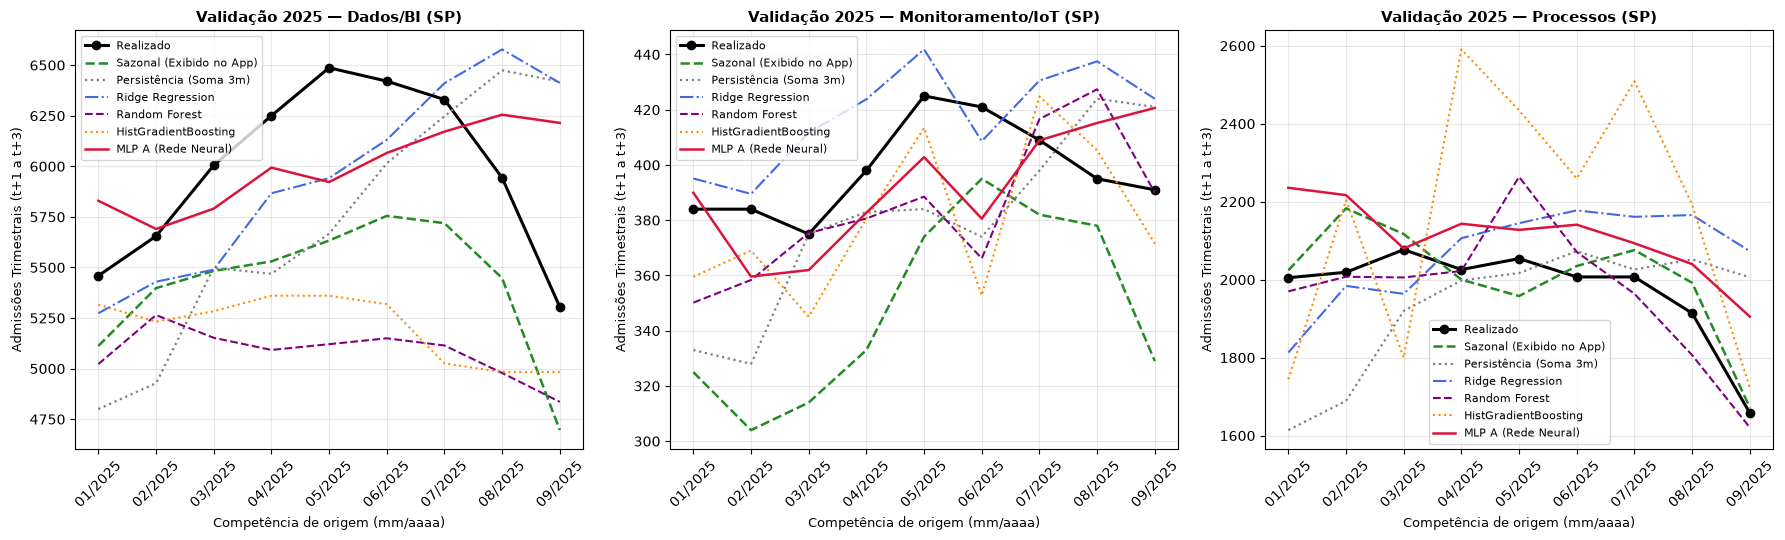

In [12]:
# 6. Avaliação — Gráfico Real vs Previsto na Validação Externa (São Paulo)
prev_r = pd.read_parquet(os.path.join(dir_rna, "previsoes.parquet"))
prev_val_r = prev_r[prev_r["modelo"] == "MLP_A_global_validacao"].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
destinos = ["analista_dados_bi", "analista_monitoramento_iot", "analista_processos"]
titulos = ["Dados/BI", "Monitoramento/IoT", "Processos"]

for i, (dest, tit) in enumerate(zip(destinos, titulos, strict=False)):
    sub_c = prev_val_c[(prev_val_c["uf"] == "35") & (prev_val_c["destino"] == dest)]
    sub_r = prev_val_r[
        (prev_val_r["uf"] == "35") & (prev_val_r["destino"] == dest)
    ].sort_values("competencia")
    sub_p = df[
        (df["uf"] == "35") & (df["destino"] == dest) & (df["particao"] == "validacao")
    ].sort_values("competencia")
    real_df = sub_c[sub_c["modelo"] == "ridge"].sort_values("competencia")

    comps = real_df["competencia"].tolist()
    labels_x = [f"{c[4:6]}/{c[:4]}" for c in comps]

    axes[i].plot(
        labels_x,
        real_df["alvo"],
        label="Realizado",
        color="black",
        linewidth=2.2,
        marker="o",
    )

    # Baselines de referência
    axes[i].plot(
        labels_x,
        sub_p["admissoes_sazonal_ano_anterior"],
        label="Sazonal (Exibido no App)",
        color="forestgreen",
        linestyle="--",
        linewidth=1.8,
    )
    axes[i].plot(
        labels_x,
        sub_p["admissoes_soma_3m"],
        label="Persistência (Soma 3m)",
        color="gray",
        linestyle=":",
        linewidth=1.6,
    )

    modelos_plot = [
        ("ridge", "Ridge Regression", "royalblue", "-."),
        ("random_forest", "Random Forest", "purple", "--"),
        ("hist_gradient_boosting", "HistGradientBoosting", "darkorange", ":"),
    ]
    for mod, rotulo, cor, ls in modelos_plot:
        sub_mod = sub_c[sub_c["modelo"] == mod].sort_values("competencia")
        axes[i].plot(
            labels_x,
            sub_mod["previsao"],
            label=rotulo,
            color=cor,
            linestyle=ls,
            linewidth=1.5,
        )

    if len(sub_r) > 0:
        axes[i].plot(
            labels_x,
            sub_r["previsao"],
            label="MLP A (Rede Neural)",
            color="crimson",
            linewidth=1.8,
        )

    axes[i].set_title(f"Validação 2025 — {tit} (SP)", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Competência de origem (mm/aaaa)", fontsize=9)
    axes[i].set_ylabel("Admissões Trimestrais (t+1 a t+3)", fontsize=9)
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].legend(fontsize=8)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "real_vs_previsto_sp.png", dpi=100)
plt.show()

### Avaliação — Visualização Real vs Previsto em São Paulo
O confronto entre os valores realizados e as estimativas dos modelos e baselines para o estado de São Paulo durante a validação externa de 2025 mostra os seguintes comportamentos visíveis:
- **Dados/BI (`analista_dados_bi`):** As admissões sobem continuamente de 5.459 (origem 202501) até o pico de 6.487 (origem 202505), mantendo-se elevadas em 5.943 em 202508. Na competência 202509, ocorre uma desaceleração brusca para 5.305 admissões realizadas; nenhum modelo acompanha plenamente essa queda pontual. Ridge (6.412,2) e MLP A (6.214,6) superestimam as admissões ao refletirem a forte inércia da persistência recente (6.419), enquanto o Random Forest (4.835,9) e o HistGradientBoosting (4.983,3) subestimam o nível. O baseline sazonal estimava 4.696 para esse ponto.
- **Processos (`analista_processos`):** As contratações mantêm patamar estável entre 2.000 e 2.077 admissões de 202501 a 202507, arrefecendo para 1.914 em 202508 e 1.658 em 202509. Na origem 202509, o Random Forest (1.621,0) e o Sazonal (1.672) ficaram mais próximos do realizado (1.658) do que o Ridge (2.073,2) e a MLP A (1.905,1).
- **Monitoramento/IoT (`analista_monitoramento_iot`):** Apresenta escala reduzida e estável (realizado entre 375 e 425 admissões trimestrais). Em 202509, com realizado de 391, todas as estimativas oscilam na mesma faixa estreita: sazonal em 329, persistência em 421, Ridge em 424,0, Random Forest em 390,0, HistGradientBoosting em 371,5 e MLP em 420,6.

In [13]:
# 6. Avaliação — Análise de Séries Críticas (Maiores e Menores Erros)
tabela_series_classicos = val_c["modelos"]["ridge"]["tabela_series"]
df_series_ridge = pd.DataFrame(tabela_series_classicos)
cols_show = ["destino", "uf", "mae", "rmse", "wape", "mase"]

print("Top 5 Séries com Maior MAE na Validação (Ridge):")
print(
    df_series_ridge.sort_values("mae", ascending=False)
    .head(5)[cols_show]
    .to_string(index=False)
)

print("\nTop 5 Séries com Menor MAE na Validação (Ridge):")
print(
    df_series_ridge.sort_values("mae", ascending=True)
    .head(5)[cols_show]
    .to_string(index=False)
)

Top 5 Séries com Maior MAE na Validação (Ridge):
           destino uf        mae       rmse     wape     mase
 analista_dados_bi 35 440.894491 528.661344 0.073680 0.291293
analista_processos 35 167.078509 198.438768 0.084635 0.631597
 analista_dados_bi 33 111.388240 133.719606 0.159177 0.809377
analista_processos 33  82.103616  93.479602 0.155598 0.615675
 analista_dados_bi 31  59.036565  80.719471 0.087318 0.375021

Top 5 Séries com Menor MAE na Validação (Ridge):
                   destino uf       mae      rmse     wape     mase
        analista_processos 23  7.086575  8.726338 0.098122 0.596067
analista_monitoramento_iot 52  7.366651  9.898040 0.411800 1.691323
analista_monitoramento_iot 43  8.789143 11.543297 0.237544 0.505769
         analista_dados_bi 25  9.680897 14.440922 0.230498 0.809740
analista_monitoramento_iot 42 10.415677 12.845805 0.214021 0.752336


### Avaliação — Decisão Honesta de Escolha do Modelo e Limitações
- **Critério de Promoção D10a:** Pela governança do projeto, um modelo é promovido ao número mostrado ao usuário só se o MAE de validação ficar ≥ 5% abaixo do melhor baseline E o desvio do WAPE entre folds for menor que o ganho; a decisão final depende da avaliação no holdout 2026, que está fechado.
- **Modelos Clássicos não Promovidos:** Como nenhum modelo clássico superou o Baseline Sazonal no MAE (Sazonal: 33,60 vs Ridge: 34,26 e RF: 35,63), nenhum modelo clássico atende aos requisitos de promoção.
- **Situação da MLP (RNA):** A MLP A obteve MAE de 31,65 na validação externa (−5,78% vs sazonal de 33,60). Embora essa redução supere isoladamente a primeira condição (≥ 5%), isso **não é promoção**: o desvio do WAPE entre folds precisa ser estritamente menor que o ganho e a confirmação final depende da avaliação no holdout 2026, que permanece rigorosamente fechado. Por isso, a MLP permanece como estimador candidato em observação no painel técnico R06.
- **Papel do Baseline no App:** Por integridade metodológica e respeito ao usuário, a interface do aplicativo expõe as estimativas do **Baseline Sazonal**.
- **Ressalva Metodológica:** As 495 observações da validação possuem sobreposição temporal de horizontes trimestrais (janelas móveis t+1 a t+3), não sendo observações estatisticamente independentes.

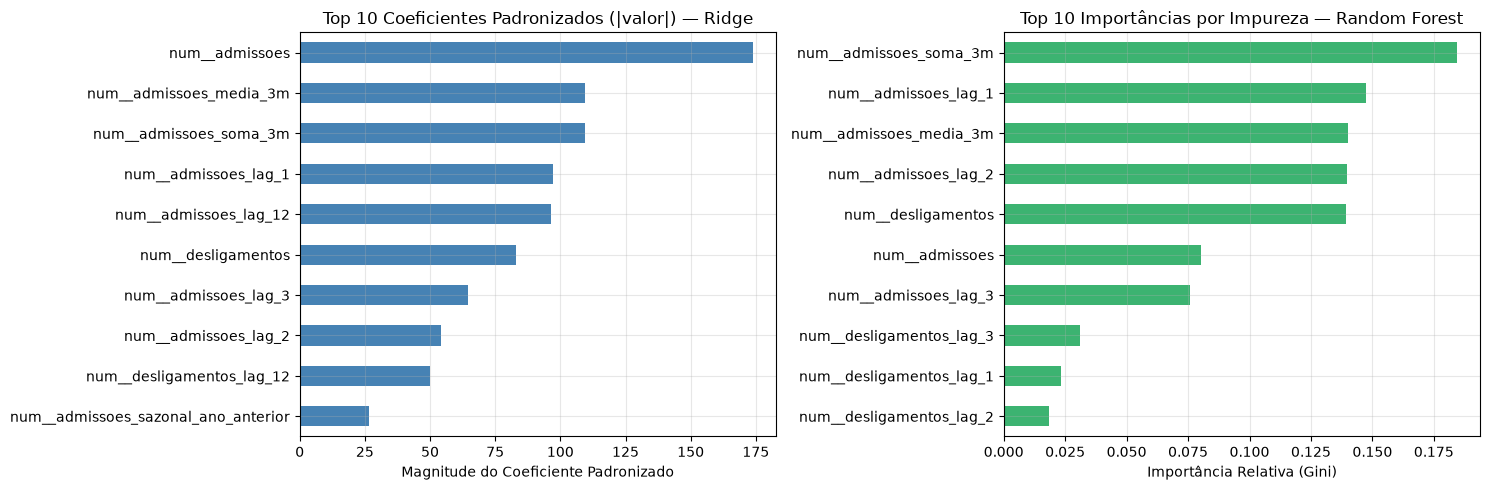

Top 5 variáveis Ridge (|coef|):
 num__admissoes             174.031531
num__admissoes_media_3m    109.432948
num__admissoes_soma_3m     109.432948
num__admissoes_lag_1        97.359547
num__admissoes_lag_12       96.240642
dtype: float64

Top 5 variáveis Random Forest:
 num__admissoes_soma_3m     0.184546
num__admissoes_lag_1       0.147191
num__admissoes_media_3m    0.139986
num__admissoes_lag_2       0.139846
num__desligamentos         0.139408
dtype: float64


In [14]:
# 7. Interpretação — Importâncias do Random Forest e Coeficientes do Ridge
coef_ridge = pd.Series(rel_c["coeficientes_ridge"])
imp_rf = pd.Series(rel_c["importancias_rf"])

top_coef = coef_ridge.abs().sort_values(ascending=False).head(10)
top_imp = imp_rf.sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_coef.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 Coeficientes Padronizados (|valor|) — Ridge", fontsize=12)
axes[0].set_xlabel("Magnitude do Coeficiente Padronizado", fontsize=10)
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3)

top_imp.plot(kind="barh", ax=axes[1], color="mediumseagreen")
axes[1].set_title("Top 10 Importâncias por Impureza — Random Forest", fontsize=12)
axes[1].set_xlabel("Importância Relativa (Gini)", fontsize=10)
axes[1].invert_yaxis()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "importancia_features.png", dpi=100)
plt.show()

print("Top 5 variáveis Ridge (|coef|):\n", top_coef.head(5))
print("\nTop 5 variáveis Random Forest:\n", top_imp.head(5))

## 7. Interpretação — Feature Importance e Coeficientes
A interpretação dos estimadores revela:
1. **Dominância de Inércia Autorregressiva:** As variáveis de defasagem recente (`admissoes_soma_3m`, `admissoes_lag_1`, `admissoes_lag_2` e desligamentos) dominam tanto os coeficientes de Ridge quanto os ganhos de impureza no Random Forest.
2. **Ausência de Interpretação Causal:** Estes coeficientes indicam correlações estatísticas de persistência temporal e escala de contratação, **não configurando relação de causa e efeito**. O aumento do volume recente de contratações é preditor de inércia contínua, e não uma recomendação normativa de mercado.

In [15]:
# 8. Aplicação — Demonstração Prática em 3 Cenários Reais (Origem 202509, SP)
origem = "202509"
exemplos_demonstracao = []

for dest in destinos:
    linha_p = df[
        (df["competencia"] == origem) & (df["uf"] == "35") & (df["destino"] == dest)
    ].iloc[0]
    mask_c = (
        (prev_val_c["competencia"] == origem)
        & (prev_val_c["uf"] == "35")
        & (prev_val_c["destino"] == dest)
    )
    prevs_c = prev_val_c[mask_c]
    mask_r = (
        (prev_val_r["competencia"] == origem)
        & (prev_val_r["uf"] == "35")
        & (prev_val_r["destino"] == dest)
    )
    prev_r_sub = prev_val_r[mask_r]

    ridge_val = prevs_c[prevs_c["modelo"] == "ridge"]["previsao"].values[0]
    rf_val = prevs_c[prevs_c["modelo"] == "random_forest"]["previsao"].values[0]
    hgb_val = prevs_c[prevs_c["modelo"] == "hist_gradient_boosting"]["previsao"].values[0]
    mlp_val = prev_r_sub["previsao"].values[0] if len(prev_r_sub) > 0 else np.nan

    exemplos_demonstracao.append({
        "Destino": dest,
        "Admissões Mês Atual": linha_p["admissoes"],
        "Soma Recente 3m": linha_p["admissoes_soma_3m"],
        "Sazonal Ano Ant.": linha_p["admissoes_sazonal_ano_anterior"],
        "Ridge": ridge_val,
        "Random Forest": rf_val,
        "HistGradBoost": hgb_val,
        "MLP (RNA)": mlp_val,
        "Realizado t+1..t+3": linha_p["alvo"],
    })

df_exemplos = pd.DataFrame(exemplos_demonstracao)
print(f"Exemplos de Previsão para Origem {origem} (UF SP):\n")
print(df_exemplos.to_string(index=False))

Exemplos de Previsão para Origem 202509 (UF SP):

                   Destino  Admissões Mês Atual  Soma Recente 3m  Sazonal Ano Ant.       Ridge  Random Forest  HistGradBoost   MLP (RNA)  Realizado t+1..t+3
         analista_dados_bi               1994.0           6419.0            4696.0 6412.181919    4835.928471    4983.340874 6214.589355              5305.0
analista_monitoramento_iot                121.0            421.0             329.0  423.956477     389.947212     371.539733  420.638062               391.0
        analista_processos                645.0           2006.0            1672.0 2073.170653    1621.016439    1723.201012 1905.147705              1658.0


## 8. Aplicação Prática ao Contexto CitizenTech
Ao acessar o módulo de mercado do CitizenTech, o profissional graduado em transição de carreira seleciona seu território (ex.: São Paulo) e a ocupação desejada:
- **Contexto, não Veredito:** A plataforma apresenta as admissões formais estimadas para o trimestre seguinte (ex.: para Dados/BI em SP na origem 202509, o app expõe a estimativa retrospectiva do baseline sazonal de 4.696 admissões, contra um realizado de 5.305), indicando a liquidez e dinamismo do mercado formal.
- **Apoio ao Planejamento:** O indicador permite comparar o ritmo de contratações formais entre diferentes caminhos de especialização, auxiliando no direcionamento temporal dos estudos.
- **Limitações Declaradas:** A métrica não mede postos informais, contratações por pessoas jurídicas (PJ) ou cooperativas, restringindo-se estritamente ao regime CLT com nível superior registrado no Novo Caged.

## 9. Síntese Crítica Final e Considerações

#### Q&A Metodológico
- **Qual foi o principal aprendizado empírico deste ciclo?**
  A forte inércia e sazonalidade das contratações formais no Brasil tornam os baselines heurísticos muito competitivos. Nenhum modelo clássico de Machine Learning superou o Baseline Sazonal no conjunto de validação de 2025 (MAE do sazonal: 33,60 vs Ridge: 34,26 e Random Forest: 35,63).
- **Por que nenhum modelo clássico foi promovido para substituir o baseline?**
  A regra D10a estabelece que a promoção ao número mostrado ao usuário exige que o MAE de validação fique ≥ 5% abaixo do melhor baseline E o desvio do WAPE entre folds seja menor que o ganho, com confirmação final no holdout fechado de 2026. Como os modelos clássicos não superaram o baseline na validação externa, promovê-los configuraria falsa promessa tecnológica. A MLP alcançou −5,78% de MAE vs sazonal na validação (o que passaria apenas a 1ª condição isolada), mas isso não é promoção e a rede segue em avaliação técnica no painel R06 enquanto o app exibe com transparência o baseline sazonal.
- **Quais são os limites éticos dos dados utilizados?**
  Os dados cobrem exclusivamente o mercado de trabalho formal sob o regime da CLT com nível superior. O modelo não deve ser interpretado como probabilidade individual de contratação, mas sim como uma estimativa agregada de dinamismo setorial e territorial de admissões.

#### Próximos Passos
1. Conclusão da interface de usuário no frontend web para exploração das estimativas.
2. Realização da rodada de avaliação cega no holdout fechado de 2026.
3. Decisão colegiada de governança (D10a) sobre a promoção ou retenção da MLP em produção.